# Particle, heat, and semiconductor carrier diffusion

Particle density, temperature excess, and excess carrier density obey
closely related diffusion equations. Their mathematical operators agree, but
the fields, transport coefficients, units, and conserved integrals remain
physically distinct.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Semidiscrete propagation

A periodic centered Laplacian is diagonalized once. Three initial fields are
expanded in the same eigenvectors and propagated with different transport
coefficients.


In [2]:
domain_length = 20.0
grid_size = 256
coordinate = np.linspace(
    -domain_length / 2.0,
    domain_length / 2.0,
    grid_size,
    endpoint=False,
)
spacing = domain_length / grid_size
sample_times = np.array([0.0, 0.5, 2.0, 6.0])

laplacian = (
    np.diag(-2.0 * np.ones(grid_size))
    + np.diag(np.ones(grid_size - 1), 1)
    + np.diag(np.ones(grid_size - 1), -1)
) / spacing**2
laplacian[0, -1] = 1.0 / spacing**2
laplacian[-1, 0] = 1.0 / spacing**2

eigenvalue, eigenvector = np.linalg.eigh(laplacian)

def propagate(initial_field, coefficient):
    spectral_coefficient = eigenvector.T @ initial_field
    return np.array([
        eigenvector @ (
            np.exp(coefficient * eigenvalue * time_value)
            * spectral_coefficient
        )
        for time_value in sample_times
    ])

particle_diffusivity = 2.0
thermal_diffusivity = 0.70
carrier_diffusivity = 1.15

particle_initial = np.exp(-(coordinate / 0.65) ** 2)
particle_initial /= spacing * np.sum(particle_initial)
particle_density = propagate(particle_initial, particle_diffusivity)

temperature_background = 300.0
temperature_excess_initial = 40.0 * np.exp(-(coordinate / 0.65) ** 2)
temperature = temperature_background + propagate(
    temperature_excess_initial,
    thermal_diffusivity,
)

carrier_background = 1.0e15
carrier_excess_initial = 4.0e15 * np.exp(-(coordinate / 0.65) ** 2)
carrier_density = carrier_background + propagate(
    carrier_excess_initial,
    carrier_diffusivity,
)


## Verification

Periodic diffusion conserves the spatial integral of each transported excess
field. The temperature and carrier backgrounds are subtracted before their
conserved excesses are evaluated.


In [3]:
particle_total = spacing * np.sum(particle_density, axis=1)
thermal_excess_total = spacing * np.sum(
    temperature - temperature_background,
    axis=1,
)
carrier_excess_total = spacing * np.sum(
    carrier_density - carrier_background,
    axis=1,
)

assert np.allclose(particle_total, particle_total[0], atol=1.0e-11)
assert np.allclose(thermal_excess_total, thermal_excess_total[0], rtol=1.0e-12)
assert np.allclose(carrier_excess_total, carrier_excess_total[0], rtol=1.0e-12)
print("particle integral:", particle_total)
print("thermal-excess relative change:", thermal_excess_total / thermal_excess_total[0] - 1.0)
print("carrier-excess relative change:", carrier_excess_total / carrier_excess_total[0] - 1.0)


particle integral: [1. 1. 1. 1.]
thermal-excess relative change: [0.00000000e+00 2.15383267e-14 6.83897383e-14 1.23678845e-13]
carrier-excess relative change: [0.00000000e+00 3.44169138e-14 9.50350909e-14 1.41886503e-13]


## Instructive plot

The first three panels retain the physical units of each field. The final panel
normalizes the three conserved integrals, demonstrating shared conservation
without implying that the fields themselves are interchangeable.


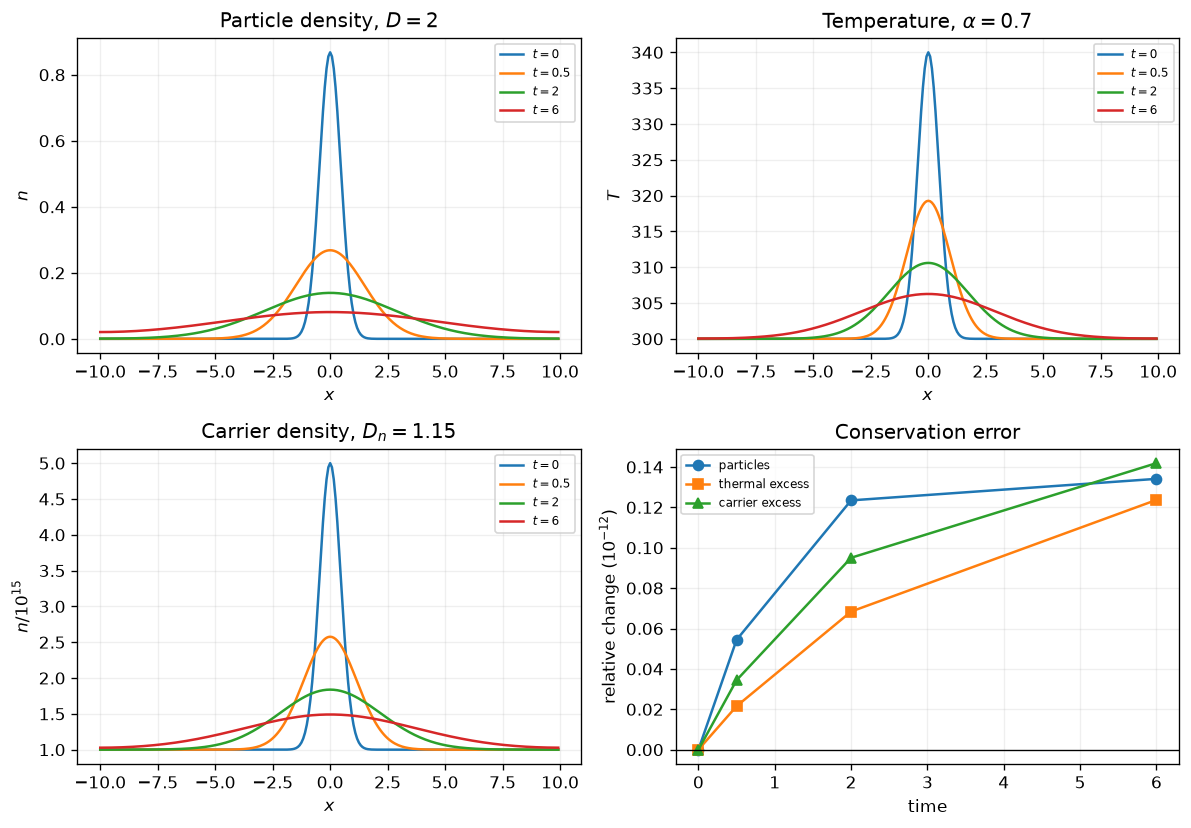

wrote lecture-notes/figures/08_brownian-motion-diffusion/11-particle-heat-and-carrier-diffusion.pdf


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(10.0, 7.0))

for index, time_value in enumerate(sample_times):
    axes[0, 0].plot(coordinate, particle_density[index], label=rf"$t={time_value:g}$")
axes[0, 0].set(title=rf"Particle density, $D={particle_diffusivity:g}$", xlabel=r"$x$", ylabel=r"$n$")
axes[0, 0].legend(fontsize=7)

for index, time_value in enumerate(sample_times):
    axes[0, 1].plot(coordinate, temperature[index], label=rf"$t={time_value:g}$")
axes[0, 1].set(title=rf"Temperature, $\alpha={thermal_diffusivity:g}$", xlabel=r"$x$", ylabel=r"$T$")
axes[0, 1].legend(fontsize=7)

for index, time_value in enumerate(sample_times):
    axes[1, 0].plot(coordinate, carrier_density[index] / 1.0e15, label=rf"$t={time_value:g}$")
axes[1, 0].set(title=rf"Carrier density, $D_n={carrier_diffusivity:g}$", xlabel=r"$x$", ylabel=r"$n/10^{{15}}$")
axes[1, 0].legend(fontsize=7)

conservation_scale = 1.0e12
axes[1, 1].plot(
    sample_times,
    conservation_scale * (particle_total / particle_total[0] - 1.0),
    "o-",
    label="particles",
)
axes[1, 1].plot(
    sample_times,
    conservation_scale * (
        thermal_excess_total / thermal_excess_total[0] - 1.0
    ),
    "s-",
    label="thermal excess",
)
axes[1, 1].plot(
    sample_times,
    conservation_scale * (
        carrier_excess_total / carrier_excess_total[0] - 1.0
    ),
    "^-",
    label="carrier excess",
)
axes[1, 1].axhline(0.0, color="black", linewidth=0.8)
axes[1, 1].set(
    title="Conservation error",
    xlabel="time",
    ylabel=r"relative change ($10^{-12}$)",
)
axes[1, 1].legend(fontsize=7)

for axis in axes.flat:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "11-particle-heat-and-carrier-diffusion.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
